In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from adjustText import adjust_text

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'mesencoder')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencoder')

In [3]:
celltypes = [
    'Epiblast',
    'Posterior Epiblast',
    'Lateral Plate Mesoderm',
    'Neuromesodermal Progenitor',
    'Presomitic Mesoderm']

In [252]:
src_early = ('GSE162534', 'GSE229103')
get_pth = lambda src: os.path.join(pth_feat, f'{src}.csv')
get_feat = lambda pth: pd.read_csv(pth).mmusculus.values
feat_dict = {src : get_feat(get_pth(src)) for src in src_early}
g = np.union1d(feat_dict[src_early[0]], feat_dict[src_early[1]])

In [253]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata = adata[adata.obs.celltype.isin(celltypes), g].copy()
adata

AnnData object with n_obs × n_vars = 11243 × 150
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [271]:
# select: early cells (only)
adata1_early = adata[adata.obs.t_bin.isin(['0']) & (adata.obs.source == 'GSE162534')].copy()
adata1_early

AnnData object with n_obs × n_vars = 1146 × 150
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'correlation', 't_bin'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [272]:
# compute module correlations
X = pd.DataFrame(adata1_early.X.toarray(),
                 index = adata1_early.obs_names,
                 columns = adata.var_names)
X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
R = pd.DataFrame(index = X.columns)
mod1 = adata1_early.obs[src_early[0]].values[:, None]
mod2 = adata1_early.obs[src_early[1]].values[:, None]
R['Mes1'] = pearsonr(X, mod1, axis = 0).statistic
R['Mes2'] = pearsonr(X, mod2, axis = 0).statistic
rank = (R.Mes2 - R.Mes1).rank().astype(int)
R = R.loc[rank.sort_values().index].copy()

# module labels
msk1 = R.index.isin(feat_dict[src_early[0]])
msk2 = R.index.isin(feat_dict[src_early[1]])
msk_dict = {'Mes1' : msk1 & ~msk2,
            'Mes2' : ~msk1 & msk2,
            'Both' : msk1 & msk2}
for mod, msk in msk_dict.items():
    R.loc[msk, 'Module'] = mod
    print(mod, msk.sum())
R['Module'] = pd.Categorical(R.Module,
                             reversed(msk_dict.keys()),
                             ordered = True)

Mes1 52
Mes2 69
Both 27


In [273]:
c_dict = {'Mes1' : 'magenta',
          'Mes2' : 'lime',
          'Both' : 'darkgrey'}

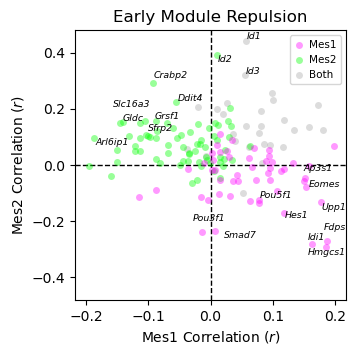

In [274]:
# plot early module repulsion
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
for mod, sdf in R.groupby('Module', observed = True):
    sdf.plot(kind = 'scatter', x = 'Mes1', y = 'Mes2',
             color = c_dict[mod], label = mod, s = 25,
             alpha = .4, linewidth = 0, ax = ax)
ax.axvline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
ax.axhline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
xlim = abs(np.asarray(ax.get_xlim())).max()
ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)

# label top genes
n, fs, texts = 10, 6.75, list()
for ix in R.head(n).index:
    texts.append(ax.text(
        R.loc[ix].Mes1,
        R.loc[ix].Mes2,
        ix, fontsize = fs,
        fontstyle = 'italic'))
for ix in R.tail(n).index:
    texts.append(ax.text(
        R.loc[ix].Mes1,
        R.loc[ix].Mes2,
        ix, fontsize = fs,
        fontstyle = 'italic'))
adjust_text(texts = texts)

for label in texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in ('T', 'Pcdh19'):
        label.set_position([x -.025, y])

ax.legend(handlelength = 1,
          handletextpad = .5,
          fontsize = 7.5,
          reverse = True)

ax.set_title('Early Module Repulsion')
ax.set_xlabel(r'Mes1 Correlation ($r$)')
ax.set_ylabel(r'Mes2 Correlation ($r$)')
# fn = os.path.join(pth_out, 'bifurcation', 'repulsion.pdf')
# plt.savefig(fn, bbox_inches = 'tight')
plt.show()